# 08. A penicillin fermenter, batch by batch: are the links between sensors straight or curved?

**Why this plant.** The metal etcher (notebook 07) gave the project's first "yes": a curved share whose whole range lay above +3 points. But the curved-link detector did not beat the straight-link one there. This notebook asks the same questions of a second batch process, much larger and with a known chemistry that should bend: a 100,000-litre penicillin fermentation.

**The data.** IndPenSim, a detailed simulation of an industrial penicillin plant (Goldrick, Duran-Villalobos, Jankauskas, Lovett, Farid and Lennox, *Computers and Chemical Engineering* 130, 106471, 2019; data on Mendeley Data, doi:10.17632/pdnjz7zz5x, CC BY 4.0). There are 100 batches, each run for about 200 to 290 hours with one reading every 12 minutes. They are run three ways: batches 1 to 30 follow a fixed **recipe**, 31 to 60 are run by **operators**, and 61 to 90 by an **advanced process controller (APC)** that uses a Raman spectrometer. Batches 91 to 100 contain faults.

**Words used here** (as in notebook 07):

- **Batch**: one fermentation from start to harvest.
- **Stage**: where in its batch a reading was taken, in tenths of the batch's length: 0–10%, 10–20%, … 90–100%. The stage plays the part the operating mode played in notebook 06.
- **Straight share**: how much of a sensor's movement a straight-line model can predict from the other sensors, on batches the model never saw (1 = all of it).
- **Curved share**: how much *more* a flexible model predicts, in *points*.
- **Range**: a 90% range from redoing the sum many times with the batches drawn at random, with repeats.
- **Catch rate at 1 false alarm in 100**: the share of faulty readings a detector flags, with its alarm line set so that 1 normal reading in 100 crosses it.

**The rules, fixed before the data was read** (section 4 has the details):

1. Only the plant's online measurements and controller outputs are used, and not those that never move in normal batches.
2. The batch is the unit. Whole batches are held out in five rounds, and every round keeps all three ways of running in the fitted set. Ranges come from resampling batches.
3. Measures as in notebook 07: the pooled, same-moment curved share (the headline); the same with the stage told to the straight model; with the control strategy told; inside each stage; lags as support; and the share of each sensor's movement between stages and between strategies.
4. **The "yes" rule**: the headline's whole 90% range above +3 points. If it clears +3 but falls below +1 once the stage is told, it is reported as level shifts between stages, not curves.
5. The outlier rule, by batch.
6. Every sensor gaining over 10 points from curves is plotted against its best single predictor, coloured by stage, and its shape labelled.
7. Detectors: fitted on 60 normal batches; the alarm line is set on the other 30 (10 per strategy), which fit nothing, as one line for all strategies. Because the faulty batches all follow the recipe, a line set on the recipe batches alone is shown too.

## 1. The batches

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import pandas as pd

from adlab import batch, explore, indpensim, plots, run

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", explore.tidy)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)

indpensim.download()      # about 0.5 GB the first time; nothing if already there
labels = indpensim.check_labels()
print("Batches:", len(labels), "| a new batch starts", labels.attrs["time restarts"], "times in the file")
labels.groupby("strategy").agg(batches=("readings", "size"), fewest_readings=("readings", "min"),
                               most_readings=("readings", "max"), shortest_hours=("hours", "min"), longest_hours=("hours", "max"))

unpacking IndPenSim: 0it [00:00, ?it/s]

Batches: 100 | a new batch starts 100 times in the file


,batches,fewest_readings,most_readings,shortest_hours,longest_hours
strategy,,,,,
APC,30,835,1205,167,241
operator,30,965,1310,193,262
recipe,40,895,1450,179,290


**What this shows.** All 100 batches are in the file, each starting again from time 0. The recipe batches (1 to 30, and the faulty 91 to 100) run 179 to 290 hours, the operator batches 193 to 262, and the APC batches 167 to 241. Only the zip file was downloaded (0.5 GB, checked against the checksum Mendeley publishes); it unpacks to a 2.6 GB table, of which only the 39 process columns are kept, in a 6 MB file under `data/raw/indpensim/`. Nothing is committed.

## 2. The columns, and which are kept

*Listed before anything was computed.* The table's 2,239 columns are 39 process columns and 2,200 Raman intensities. Each process column is put in one group: online measurements, controller outputs (settings the control system moves), offline lab assays, the simulator's own states (which a real plant could not measure online), time, and ids or flags.

**One thing to know about the file.** The headers of its last seven process columns are shifted. The dataset's own note says the batch number sits under the column headed "2-PAT control". The values confirm it: the column headed "1- No Raman spec" holds the Raman-controller flag (2 for batches 61 to 90), the column headed "Batch reference" holds the per-batch fault flag, and the two columns headed "Batch ID" and "Fault flag" hold Raman intensities. The groups below follow the values, not the headers.

In [2]:
indpensim.column_table()

,role,what it is,share missing (normal batches),moves in normal batches
column,,,,
time,time,hours since the batch started,0,True
aeration,controller output,air flow into the vessel (L/h),0,True
agitator,controller output,agitator speed (RPM),0,False
sugar feed,controller output,sugar feed rate (L/h),0,True
acid flow,controller output,acid added to hold the pH (L/h),0,True
base flow,controller output,base added to hold the pH (L/h),0,True
cooling water,controller output,heating/cooling water flow to hold the temperature (L/h),0,True
heating water,controller output,heating water flow (L/h),0,True
dilution water,controller output,water added for dilution (L/h),0,True


**What this shows.** Kept: the 9 online measurements (dissolved oxygen, volume, weight, pH, temperature, carbon dioxide and oxygen in the exhaust gas, the oxygen uptake rate and the carbon dioxide evolution rate) and 11 of the 13 controller outputs, **20 columns** in all. The agitator speed and the ammonia shots never move in normal batches, so they are left out. Also left out: the 5 offline lab assays (missing 98% of the time; a lab sample is taken now and then), the 3 simulator states (sugar and penicillin concentration, heat generated), the time, the ids and flags, and the Raman spectra.

## 3. The faulty batches

The file marks every reading of a faulty batch with 0 or 1: whether a fault is acting at that moment. These flags are the labels used below. The paper does not say which fault each of these ten batches carries; batches with exactly the same fault timing are taken to carry the same kind of fault and share a letter.

In [3]:
display(indpensim.fault_spans())
print("Faulty batches with the same fault timing share a letter:", indpensim.fault_kind_labels())

,strategy,readings,hours,fault starts (h),fault ends (h),readings with fault,stretches
batch,,,,,,,
91,recipe,1290,258,20,214,203,3
92,recipe,1150,230,80,160,122,2
93,recipe,1050,210,70,90,101,1
94,recipe,1150,230,20,110,72,2
95,recipe,1055,211,20,211,188,3
96,recipe,1150,230,70,90,101,1
97,recipe,1125,225,20,214,203,3
98,recipe,1150,230,80,160,122,2
99,recipe,1255,251,20,110,72,2


Faulty batches with the same fault timing share a letter: {91: 'A', 92: 'B', 93: 'C', 94: 'D', 95: 'E', 96: 'C', 97: 'A', 98: 'B', 99: 'D', 100: 'D'}


**What this shows.** All ten faulty batches follow the **recipe**. Faults start 20, 70 or 80 hours into a batch, and most switch on and off: they act in 1 to 3 separate stretches. Only about 11% of the readings of the faulty batches are faulty. The timings fall into five groups, A to E: A (batches 91, 97), B (92, 98), C (93, 96), D (94, 99, 100) and E (95).

## 4. Which batches are fitted on, and which are held out

*This section was written before anything was computed.*

**For the curved share.** The 90 normal batches, in batch order (recipe, operator, APC), are dealt to five rounds like cards, the count carrying on from one strategy to the next. In each round the batches dealt to it are held out whole and the models are fitted on all the others. So no batch is both fitted on and scored in a round, every batch is scored once, and every round fits on about four fifths of every strategy (rule 2). Ranges come from drawing the 90 batches at random with repeats, 500 times. The stage is the tenth of its batch a reading falls in. Lags (support only): the other sensors' readings 1, 2, 5 and 10 readings back (12 minutes to 2 hours).

**For the detectors.** Within each strategy, in batch order, every third batch sets the alarm line and the other two are fitted on: 20 fitted and 10 line batches per strategy, 60 and 30 in all. The detectors are the eight used throughout, unchanged, plus the straight-link detector told the stage. The 10 faulty batches are scored. No batch a detector was fitted on is ever scored. The main alarm line is one line for all strategies, set on all 30 line batches; beside it, a line set on the 10 recipe line batches alone.

In [4]:
display(indpensim.split_table())
indpensim.role_table()

,strategy recipe: held out,strategy recipe: fitted on,strategy operator: held out,strategy operator: fitted on,strategy APC: held out,strategy APC: fitted on
round 1,6,24,6,24,6,24
round 2,6,24,6,24,6,24
round 3,6,24,6,24,6,24
round 4,6,24,6,24,6,24
round 5,6,24,6,24,6,24


,fitted on,set the alarm line,scored
recipe,20,10,0
operator,20,10,0
APC,20,10,0
faulty (recipe),0,0,10


**What this shows.** The five rounds, each holding out 6 batches of every strategy and fitting on the other 24 of each; and the detector roles.

## 5. Does one batch dominate? (the outlier rule)

If a single batch holds more than half of any sensor's movement, results are reported with and without it, and the version without it is the headline. With 90 batches an even share is about 0.011.

In [5]:
movement, flagged = indpensim.outlier_check()
print("Batches holding more than half of any sensor's movement:", flagged or "none")
movement.head(6)

Batches holding more than half of any sensor's movement: none


,largest share,run,even share
sensor,,,
pH,0.423,67,0.011
dissolved oxygen,0.095,44,0.011
heating water,0.064,45,0.011
acid flow,0.058,51,0.011
base flow,0.053,73,0.011
cooling water,0.034,60,0.011


**What this shows.** The largest share is the pH in batch 67, about 0.42: well above an even share, but below one half. **The rule is not triggered**, so all 90 batches are used. That one batch weighs heavily on the pH, though, so the pH's own range below may be wide.

## 6. The headline measure, and the versions beside it

The first row is the headline: all 90 normal batches pooled, every reading, each of the 20 columns predicted from the other 19 at the same moment. Below it, the stage told to the straight model, the control strategy told, and the four lag sets. The first time, this takes about 25 minutes; after that the answers are read from `results/cache`.

In [6]:
pooled = indpensim.measures()
batch.measure_table(pooled)

,straight share,"straight, low","straight, high","curved share, points","curved low, points","curved high, points",sensors gaining over 5 points,sensors gaining over 10 points,held-out batches,held-out readings
measure,,,,,,,,,,
same moment (the headline),0.693,0.675,0.706,14.761,13.261,16.014,12,10,90,102410
"same moment, stage told to the straight model",0.71,0.692,0.723,13.321,12.259,14.508,10,9,90,102410
"same moment, control strategy told to the straight model",0.693,0.675,0.706,14.767,13.255,16.022,12,10,90,102410
+ 1 back,0.827,0.8,0.849,8.27,6.725,9.771,8,3,90,102320
"+ 1, 2 back",0.836,0.808,0.857,7.86,6.199,9.514,8,2,90,102230
"+ 1, 2, 5 back",0.848,0.824,0.867,7.097,5.366,8.619,7,2,90,101960
"+ 1, 2, 5, 10 back",0.864,0.851,0.876,5.989,4.725,6.927,6,2,90,101510


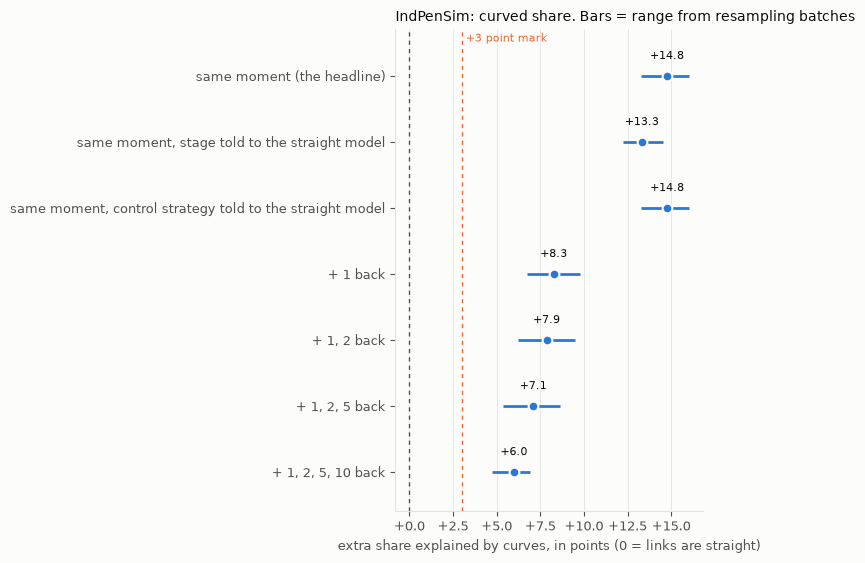

In [7]:
plots.curved_share(pooled, title="IndPenSim: curved share. Bars = range from resampling batches", mark=0.03, points=True);

**What this shows.**

- **The headline: curved share +14.8 points, range +13.3 to +16.0.** The whole range lies **above +3 points**: this is the project's second "yes", and the strongest. The straight share is 0.69. Ten of the 20 columns gain more than 10 points from curves.
- **Stage told: +13.3 points (+12.3 to +14.5).** Giving each tenth of a batch its own level takes away about 1.5 points. Under rule 4 this is **not** level shifts between stages: it stays far above +1.
- **Control strategy told: +14.8 points**, the same as without. The three ways of running the plant sit at the same levels (section 8), so telling the strategy changes nothing.
- **Lags:** +8.3, +7.9, +7.1 and +6.0 points as 1, 2, 5 and 10 readings of history are added (the last range +4.7 to +6.9, still above +3). The straight share rises from 0.69 to 0.86. About half of what the flexible model finds at the same moment, a straight model can also find from the recent past. The other half it cannot.

## 7. Sensor by sensor

The headline one column at a time, most curved first (0.10 is 10 points). The last two columns repeat it with the stage told.

In [8]:
by_sensor = indpensim.sensor_table(pooled[batch.SAME_MOMENT])
told = indpensim.sensor_table(pooled[batch.TOLD])
curved = batch.most_curved(pooled[batch.SAME_MOMENT])
print("Sensors gaining over 10 points from curves:", ", ".join(curved) or "none")
pd.concat([by_sensor, told[["straight", "curved"]].add_suffix(", stage told")], axis=1)

Sensors gaining over 10 points from curves: acid flow, broth dumped, dilution water, heating water, pH, sugar feed, temperature, base flow, PAA flow, cooling water


,what it measures,straight,curved,curved_low,curved_high,"straight, stage told","curved, stage told"
sensor,,,,,,,
acid flow,acid added to hold the pH (L/h),-0.09,0.81,0.681,1.005,-0.091,0.807
broth dumped,broth taken out of the vessel (L/h),0.083,0.513,0.487,0.544,0.086,0.508
dilution water,water added for dilution (L/h),0.569,0.277,0.264,0.29,0.698,0.15
heating water,heating water flow (L/h),0.636,0.223,0.208,0.24,0.648,0.218
pH,pH of the broth,0.089,0.182,0.005,0.261,0.071,0.231
sugar feed,sugar feed rate (L/h),0.688,0.163,0.146,0.18,0.713,0.136
temperature,broth temperature (K),0.695,0.152,0.141,0.162,0.707,0.144
base flow,base added to hold the pH (L/h),0.457,0.128,0.103,0.149,0.469,0.124
PAA flow,flow of the precursor phenylacetic acid (L/h),0.716,0.119,0.105,0.133,0.731,0.098


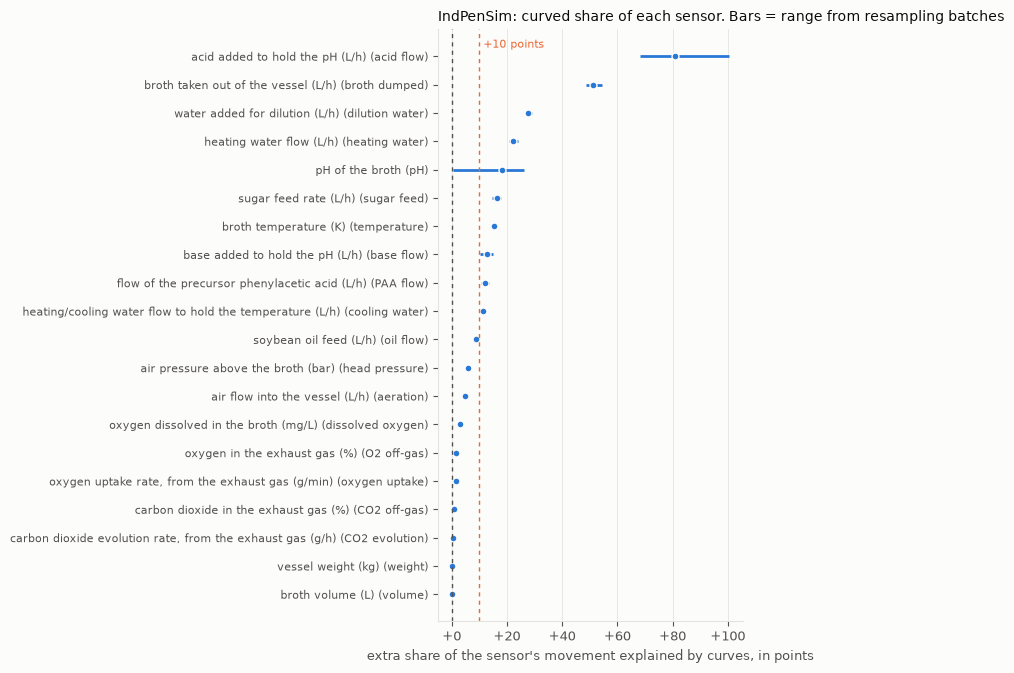

In [9]:
plots.curved_by_sensor(by_sensor, "IndPenSim: curved share of each sensor. Bars = range from resampling batches",
                       low="curved_low", high="curved_high");

**What this shows.** The curve sits in the **controller outputs**: the acid flow (+81 points, while a straight line predicts none of it), the broth taken out (+51), the dilution water (+28), the heating water (+22), the sugar feed (+16), the base flow (+13), the PAA feed (+12) and the cooling water (+11). Among the measurements, only the pH (+18) and the temperature (+15) gain over 10 points; the pH's range is wide (+0.5 to +26), because one batch (67) holds 0.42 of its movement (section 5). The exhaust-gas readings, the volume and the weight are predicted almost perfectly by straight lines (0.98 to 0.99) and gain almost nothing.

Telling the stage hardly changes the curved column, except for the dilution water (+28 to +15) and the dissolved oxygen (+3 to 0).

## 8. How much of each column's movement lies between stages, and between strategies

As in notebooks 06 and 07: if nearly all of a column's movement is the jump between a few groups, a straight model can hit every group's average and the pooled measure cannot show a curve between them.

In [10]:
indpensim.between_table()

,what it measures,share between stages,share between strategies
sensor,,,
pH,pH of the broth,0.006,0.004
acid flow,acid added to hold the pH (L/h),0.013,0.005
broth dumped,broth taken out of the vessel (L/h),0.036,0
base flow,base added to hold the pH (L/h),0.104,0.015
heating water,heating water flow (L/h),0.118,0.001
temperature,broth temperature (K),0.143,0.001
dissolved oxygen,oxygen dissolved in the broth (mg/L),0.287,0.002
cooling water,heating/cooling water flow to hold the temperature (L/h),0.347,0.002
O2 off-gas,oxygen in the exhaust gas (%),0.407,0.007


**What this shows.** **Between strategies: almost nothing** (under 0.04 for every column). The three ways of running the plant are not islands. **Between stages** it varies. Several feeds and the exhaust-gas readings follow the batch's progress (0.8 to 0.9 of their movement between tenths of the batch). But the most curved columns do not: the acid flow (0.01), the pH (0.01), the broth taken out (0.04), the base flow (0.10) and the heating water (0.12) move almost entirely *inside* each tenth of the batch. So the islands limit does not apply to them, and their curved share is not level shifts between stages.

## 9. Inside each tenth of a batch

The same measure using only the readings from one tenth of every batch, with the same rounds.

In [11]:
inside = indpensim.within_stages()
batch.measure_table(inside)

,straight share,"straight, low","straight, high","curved share, points","curved low, points","curved high, points",sensors gaining over 5 points,sensors gaining over 10 points,held-out batches,held-out readings
measure,,,,,,,,,,
0-10%,0.679,0.673,0.686,10.902,10.493,11.33,9,5,90,10250
10-20%,0.664,-14.445,0.68,9.47,8.802,1355.943,9,7,90,10232
20-30%,0.67,0.324,0.69,3.494,1.615,12.543,6,2,90,10250
30-40%,0.635,0.605,0.649,9.191,5.638,12.232,11,8,90,10232
40-50%,0.572,-0.36,0.597,8.327,6.982,51.842,8,6,90,10250
50-60%,-0.674,-7.37,0.432,14.631,10.448,20.677,10,8,90,10232
60-70%,-26.039,-82.177,0.559,11.841,9.195,14.702,7,5,90,10250
70-80%,0.372,0.013,0.506,15.553,10.121,26.036,8,7,90,10232
80-90%,0.284,-0.463,0.503,16.46,10.134,50.524,8,7,90,10250


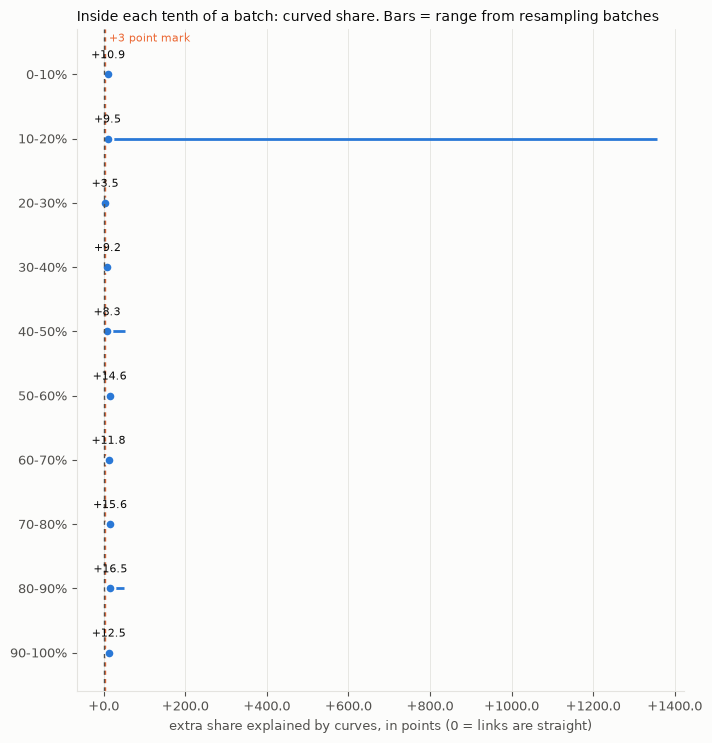

In [12]:
plots.curved_share(inside, title="Inside each tenth of a batch: curved share. Bars = range from resampling batches",
                   mark=0.03, points=True);

**What this shows.** The curved share stays large **inside every tenth of a batch**: +8 to +16 points in eight of the ten, +9.5 in 10–20% and +3.5 in 20–30%. Some ranges are unusable, for example up to +1,356 points in 10–20%, and some straight shares are far below zero (−26 in 60–70%). Inside a tenth of a batch, a few columns hardly move at all, so a small miss counts as a huge share of their movement. The middle values are steady even where the ranges are not. The curvature is inside the stages, not in the jumps between them, as on the metal etcher.

## 10. The columns that gain most from curves

Every column that gains more than 10 points from curves, plotted against the one other column that on its own says most about it, each reading coloured by stage (light = early in the batch, dark = late). One reading in three is plotted. Before the plot, numbers that help to name the shape. In the plots, a column with 20 or fewer different values is spread a little sideways around each value, so dots on the same value can be seen; for the two-valued broth outflow this spreads each value over a wide band.

,what it measures,best single predictor,share explained,which measures
sensor,,,,
acid flow,acid added to hold the pH (L/h),pH,0.4,pH of the broth
broth dumped,broth taken out of the vessel (L/h),pH,0.188,pH of the broth
dilution water,water added for dilution (L/h),CO2 evolution,0.54,"carbon dioxide evolution rate, from the exhaust gas (g/h)"
heating water,heating water flow (L/h),temperature,0.203,broth temperature (K)
pH,pH of the broth,base flow,0.266,base added to hold the pH (L/h)
sugar feed,sugar feed rate (L/h),CO2 evolution,0.676,"carbon dioxide evolution rate, from the exhaust gas (g/h)"
temperature,broth temperature (K),heating water,0.282,heating water flow (L/h)
base flow,base added to hold the pH (L/h),pH,0.263,pH of the broth
PAA flow,flow of the precursor phenylacetic acid (L/h),aeration,0.87,air flow into the vessel (L/h)


,distinct values,share at commonest value,share at its lowest,share at its highest,share between stages
sensor,,,,,
acid flow,1146,0.974,0.974,0,0.013
broth dumped,2,0.946,0.054,0.946,0.036
dilution water,6,0.331,0.268,0.11,0.517
heating water,49424,0.442,0.442,0,0.118
pH,3538,0.004,0,0,0.006
sugar feed,23,0.349,0.013,0.019,0.421
temperature,240,0.081,0,0,0.143
base flow,62180,0.027,0.024,0.027,0.104
PAA flow,22931,0.391,0.129,0,0.644


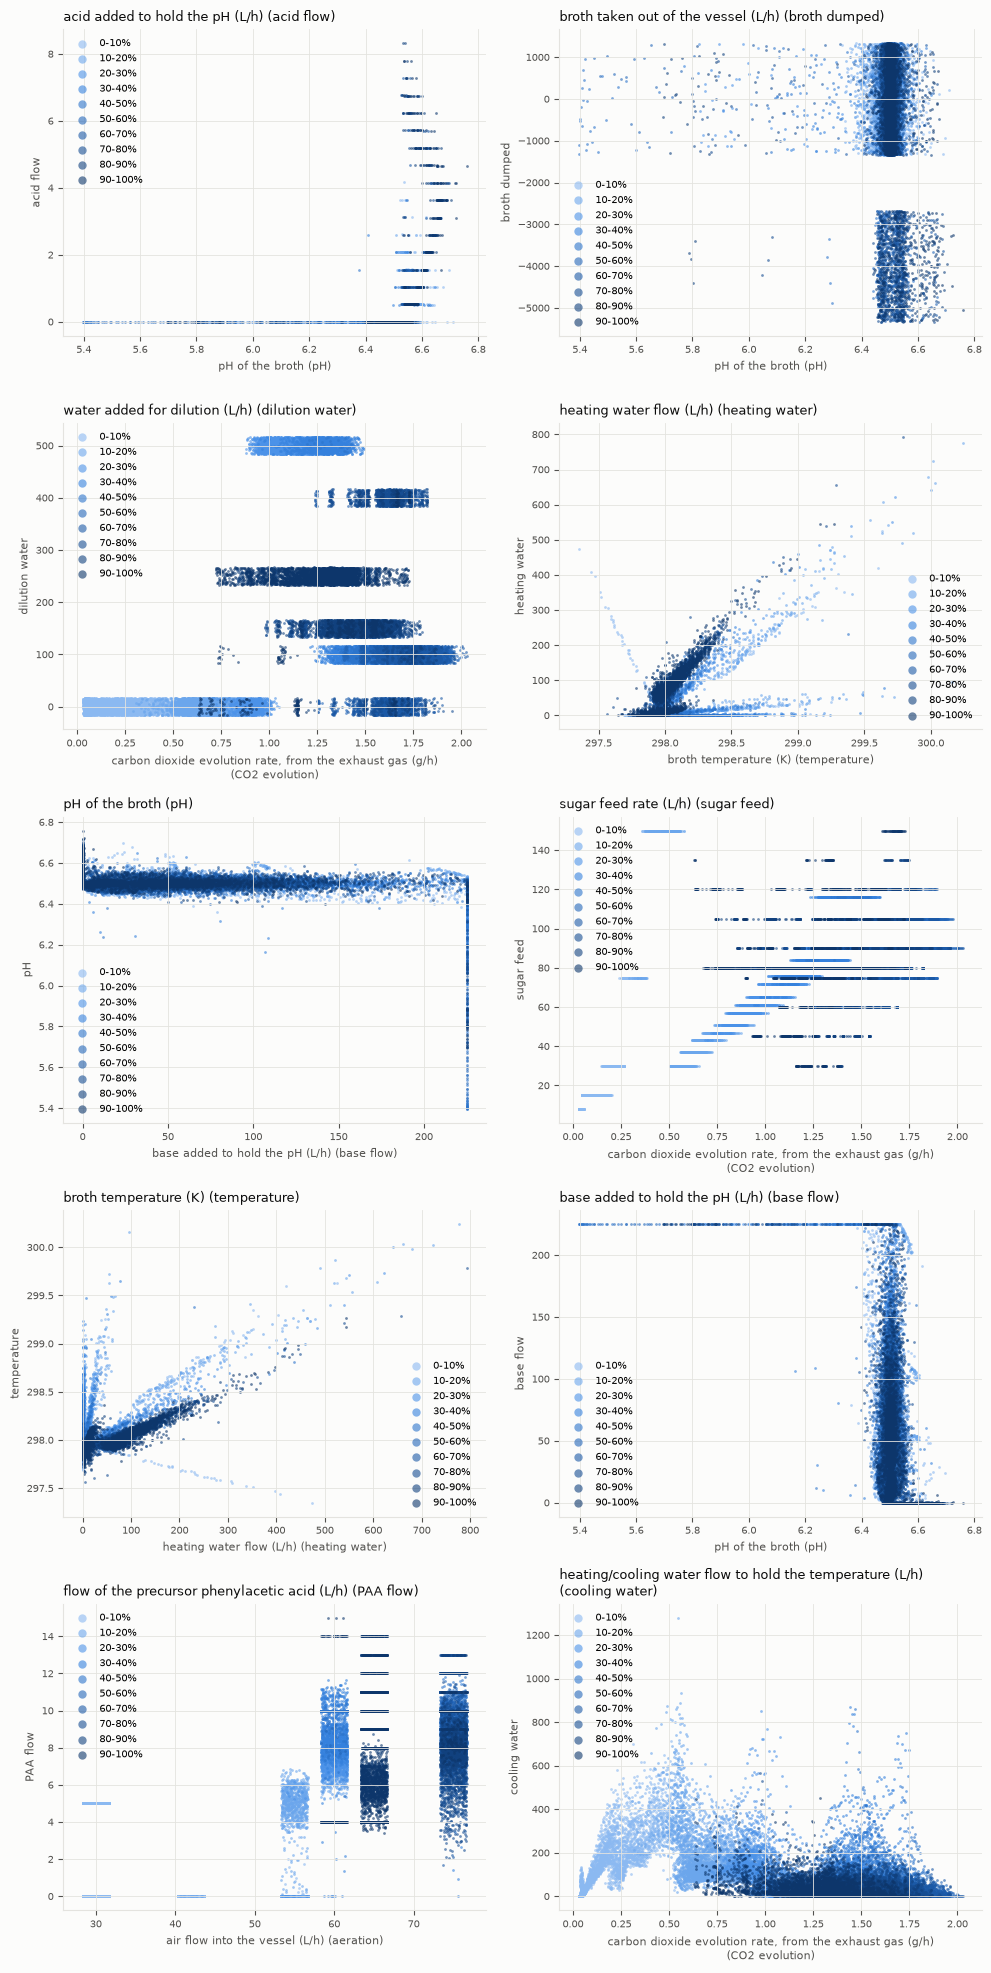

In [13]:
if curved:
    display(indpensim.best_partner(curved))
    display(indpensim.shape_clues(curved))
    indpensim.curved_scatter(curved);

**What this shows.** Most of the curve is the plant's **control system at work**: valves that switch on at a set point, pumps running flat out, and steps in the recipe. Labels (rule 6), as I read the plots and the table above:

| Column | Gain | Label | Why |
| --- | --- | --- | --- |
| acid flow | +81 | **corner** | zero while the pH is below about 6.5, then rising steeply with the pH: the acid pump only works above the set point |
| broth taken out | +51 | **two-state flip** | two values only: nothing, or the vessel being drained |
| dilution water | +28 | **separate clusters** | a few set levels, stepping as the batch goes on |
| heating water | +22 | **corner** | zero most of the time, then a straight rise with the temperature: heating and cooling share one temperature controller |
| pH | +18 | **ceiling** | when the base pump is at its limit (about 225 L/h), the pH falls freely |
| sugar feed | +16 | **separate clusters** | the recipe's feed steps, one level after another |
| temperature | +15 | **corner** | the heating water's corner seen from the other side |
| base flow | +13 | **ceiling** | pinned at its top value whenever the pH is low |
| PAA flow | +12 | **separate clusters** | grouped by the air flow's few settings |
| cooling water | +11 | **smooth curve**, loosely | a broad hump against the carbon dioxide evolution rate (rising, then falling), blurred by stage; the nearest thing here to a smooth bend |

So the second "yes" is mostly corners and ceilings in the controllers, as on the chemical plant's valves (notebook 06, section 10). Here, though, they touch half of the columns and are present all through every batch.

## 11. Detectors

The eight detectors, unchanged, plus the straight-link detector told the stage, fitted on the 60 fit batches and scored on the 10 faulty batches and the 30 line batches. A faulty reading is one whose fault flag is 1.

**Ranges.** There are only 10 faulty batches, and the faults differ a lot from batch to batch, so **the ranges are wide: about plus or minus 20 to 25 points for the best detectors.** Two detectors would need a gap of well over 12 points to be told apart.

The first table gives the catch rate at 1 false alarm in 100 under the main line (one line for all strategies, set on all 30 line batches) and under the line set on the 10 recipe line batches alone. The last table gives the false alarms on the faulty batches' own normal readings.

In [14]:
indpensim.score()           # the first time, about 20 minutes; then read from results/cache
main = indpensim.detector_report("all")
recipe = indpensim.detector_report("recipe")
pd.DataFrame({"caught, one line for all strategies": run.rates(main), "caught, line from recipe batches": run.rates(recipe)})

,"caught, one line for all strategies","caught, line from recipe batches"
detector,,
CUSUM chart,0.23 (0.14-0.33),0.23 (0.15-0.35)
Curved-link residual,0.45 (0.25-0.71),0.46 (0.26-0.71)
EWMA chart,0.38 (0.21-0.60),0.37 (0.22-0.60)
Isolation Forest,0.04 (0.01-0.07),0.04 (0.01-0.07)
Matrix Profile,0.28 (0.14-0.50),0.28 (0.14-0.51)
PCA (T2 + SPE),0.34 (0.18-0.58),0.34 (0.18-0.58)
Rolling z-score,0.37 (0.19-0.58),0.30 (0.17-0.55)
Straight-link residual,0.44 (0.25-0.70),0.44 (0.25-0.70)
"Straight-link residual, stage told",0.44 (0.25-0.70),0.44 (0.25-0.70)


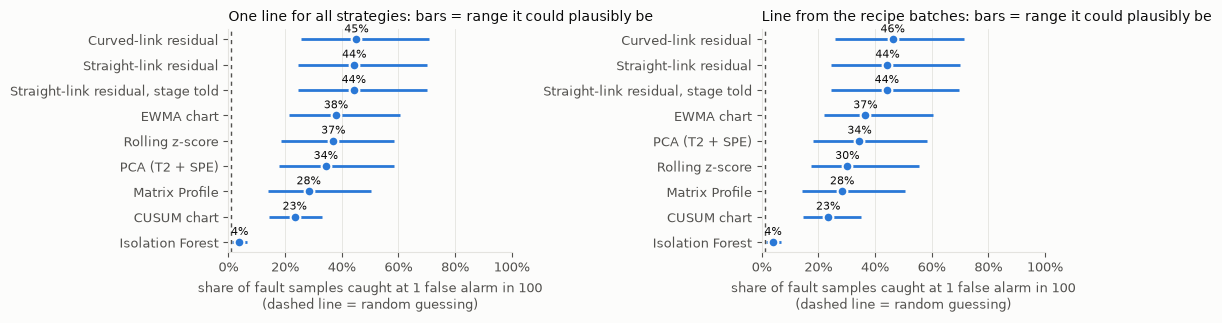

In [15]:
plots.pilot_overall({"main": main, "recipe": recipe},
                    titles={"main": "One line for all strategies", "recipe": "Line from the recipe batches"});

In [16]:
pd.DataFrame({"false alarms on the faulty batches' own normal readings, one line": pd.DataFrame(main["summary"]).set_index("method")["far_own_normal"],
              "the same, recipe line": pd.DataFrame(recipe["summary"]).set_index("method")["far_own_normal"]}).round(3)

,"false alarms on the faulty batches' own normal readings, one line","the same, recipe line"
method,,
Rolling z-score,0.039,0.034
EWMA chart,0.04,0.037
CUSUM chart,0.359,0.361
PCA (T2 + SPE),0.045,0.047
Isolation Forest,0.017,0.018
Matrix Profile,0.077,0.08
Straight-link residual,0.039,0.039
Curved-link residual,0.046,0.055
"Straight-link residual, stage told",0.039,0.039


**What this shows.**

- **The top three tie:** the curved-link detector **0.45** (0.25 to 0.71), the straight-link detector **0.44** (0.25 to 0.70) and the straight-link detector told the stage, 0.44. EWMA (0.38), the rolling z-score (0.37) and PCA (0.34) come next, then Matrix Profile (0.28), CUSUM (0.23) and Isolation Forest (0.04).
- **The recipe-only line gives the same picture** (0.46, 0.44, 0.44 for the top three). Only the rolling z-score changes much, falling from 0.37 to 0.30.
- **False alarms on the faulty batches' own normal readings are about 0.04**, four times the 0.01 the line is set for. Section 12's last table shows where they fall. Before the faults, every detector but Isolation Forest is at 0.00 to 0.01: the line carries over. The extra false alarms are on the normal readings *between* a fault's stretches. Once a fault has acted, the plant does not go straight back to normal, so "normal" readings there are not quite normal. CUSUM, which adds up deviations over time, gives 0.45 false alarms there, so its catch rate here is not a fair "1 false alarm in 100".

## 12. Which detector is ahead?

Every pair under the main line ("ahead" needs at least 12 points with a range clear of zero), then the two comparisons this task is about, and the false alarms before a fault first starts and after.

In [17]:
display(run.verdict_table(main))
pd.concat({"curved-link against": run.gap_table(main, "Curved-link residual", ["Straight-link residual"]),
           "stage-told straight-link against": run.gap_table(main, "Straight-link residual, stage told", ["Straight-link residual"])})

,Curved-link residual,Straight-link residual,"Straight-link residual, stage told",EWMA chart,Rolling z-score,PCA (T2 + SPE),Matrix Profile,CUSUM chart,Isolation Forest
row against column,,,,,,,,,
Curved-link residual,,tie,tie,tie,tie,tie,ahead,tie,ahead
Straight-link residual,tie,,tie,tie,tie,tie,ahead,tie,ahead
"Straight-link residual, stage told",tie,tie,,tie,tie,tie,ahead,tie,ahead
EWMA chart,tie,tie,tie,,tie,tie,tie,tie,ahead
Rolling z-score,tie,tie,tie,tie,,tie,tie,tie,ahead
PCA (T2 + SPE),tie,tie,tie,tie,tie,,tie,tie,ahead
Matrix Profile,behind,behind,behind,tie,tie,tie,,tie,ahead
CUSUM chart,tie,tie,tie,tie,tie,tie,tie,,ahead
Isolation Forest,behind,behind,behind,behind,behind,behind,behind,behind,


,,gap,low,high,verdict
,Curved-link residual against,,,,
curved-link against,Straight-link residual,0.008,-0.013,0.034,tie
stage-told straight-link against,Straight-link residual,-0.002,-0.004,0.001,tie


**What this shows.**

- **Curved-link against straight-link: +0.8 points (-1.3 to +3.4): a tie.** With the recipe line it is +1.8 points (-0.4 to +4.1), also a tie.
- **Stage-told against plain straight-link: -0.2 points: a tie.** Telling the stage changes almost nothing.
- Only a few gaps reach the margin: the link detectors are ahead of Matrix Profile and of Isolation Forest. With ranges this wide, everything else is a tie.

## 13. Kinds of fault

The data does not name the faults. The ten batches fall into five groups with the same fault timing (A to E, section 3); each group is taken as one kind of fault.

In [18]:
display(run.fault_table(main))
indpensim.fault_kinds()

,Curved-link residual,Straight-link residual,"Straight-link residual, stage told",EWMA chart,Rolling z-score,PCA (T2 + SPE),Matrix Profile,CUSUM chart,Isolation Forest
kind of fault,,,,,,,,,
timing A,0.01,0.02,0.02,0.03,0.03,0.02,0,0.17,0.03
timing B,0.78,0.81,0.8,0.64,0.58,0.3,0,0.15,0
timing C,0.77,0.67,0.67,0.62,0.61,0.66,0.66,0.32,0
timing D,1,1,1,0.86,0.88,1,0.99,0.31,0.16
timing E,0,0,0,0,0,0,0.04,0.3,0


,level checks,straight links,curved links,shape in time,sensors moved,kind
kind of fault,,,,,,
timing A,0.175,0.022,0.015,0.005,0,hard for all
timing B,0.635,0.807,0.779,0,1,single sensor
timing C,0.619,0.668,0.767,0.658,1,single sensor
timing D,0.875,1,1,0.986,3,single sensor
timing E,0.298,0,0,0.037,0,hard for all


**What this shows.**

- **Timing D** (batches 94, 99 and 100; on from 20 to 110 hours in two stretches) is caught almost completely by the link detectors and PCA (1.00).
- **Timings B and C** are caught 0.67 to 0.81 by the link detectors, and 0.58 to 0.66 by the level checks.
- **Timings A and E** (batches 91, 97 and 95; long faults from 20 hours, on and off) are **hard for all**. The best is CUSUM at 0.17 and 0.30, and with its false alarms that is not a real catch.
- Curved and straight links catch the same kinds, to within about 10 points (C: 0.77 against 0.67).

## 14. Summary

**Against the "yes" rule.** The headline (90 normal batches pooled, same moment) is a curved share of **+14.8 points, range +13.3 to +16.0: wholly above +3 points.** With the stage told it is **+13.3 (+12.3 to +14.5)**, far above +1: not level shifts between stages. With the control strategy told it is unchanged. It stays large inside every tenth of a batch. **This is the project's second "yes", and the strongest so far.**

**Against the deep-model test-bed condition** (clears +3 **and** the curved-link detector beats the straight-link by the margin): **not met.** Curved-link 0.45 against straight-link 0.44: +0.8 points, a tie.

**What the "yes" is made of.** Mostly **corners and ceilings in the control system**: the acid and base pumps switching on at the pH set point or running flat out, heating and cooling sharing one temperature controller, and steps in the recipe's feeds (section 10). One column (cooling water) shows something like a smooth bend. These shapes are real, and a flexible model predicts normal readings much better because of them. But catching faults does not improve: on these faults, the curved-link detector raises the same alarms as the straight-link one.

**Limits.** Only 10 faulty batches, of five unnamed kinds; ranges about plus or minus 20 to 25 points. False alarms between a fault's stretches are 4 times the target. The data and the paper do not say which fault each batch carries.

**Choices, and when they were made.**

- Before computing: the 20 columns; the stage as tenths of a batch; the rounds by strategy; the lags; the detector roles and both alarm lines; labels from the file's fault flag; fault kinds grouped by identical timing.
- After seeing results, for explanation only: the labels in section 10. No threshold or model setting was chosen after seeing results.
- The outlier rule was applied and not triggered (largest share 0.42, the pH in batch 67).